In [2]:
import pandas as pd
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense

data = pd.read_csv('/content/cifar-10.csv')
print("dataset shape : ", data.shape)
print(data.head())

dataset shape :  (7066, 3073)
   pixel_0  pixel_1  pixel_2  pixel_3  pixel_4  pixel_5  pixel_6  pixel_7  \
0       59       43       50       68       98      119      139      145   
1      154      126      105      102      125      155      172      180   
2      255      253      253      253      253      253      253      253   
3       28       37       38       42       44       40       40       24   
4      170      168      177      183      181      177      181      184   

   pixel_8  pixel_9  ...  pixel_3063  pixel_3064  pixel_3065  pixel_3066  \
0      149      149  ...        58.0        65.0        59.0        46.0   
1      142      111  ...        42.0        67.0       101.0       122.0   
2      253      253  ...        83.0        80.0        69.0        66.0   
3       32       43  ...        39.0        59.0        42.0        44.0   
4      189      189  ...        88.0        85.0        82.0        83.0   

   pixel_3067  pixel_3068  pixel_3069  pixel_3070 

In [4]:
data = data.dropna(subset=['label']).fillna(0)

x = data.drop('label', axis=1).values /255.0
y = data['label'].values.astype(int)

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

x_train = x_train.reshape(-1, 32, 32, 3)
x_test = x_test.reshape(-1, 32, 32, 3)

print(x_train.shape, x_test.shape)

(5652, 32, 32, 3) (1413, 32, 32, 3)


In [6]:
model = Sequential([
    Conv2D(32, (3,3),activation='relu', input_shape=(32,32,3)),
    MaxPooling2D((2,2)),
    Flatten(),
    Dense(64, activation='relu'),
    Dense(10,activation='softmax')
])
model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 30, 30, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 15, 15, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 7200)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │       460,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 462,410 (1.76 MB)

 Trainable params: 462,410 (1.76 MB)

 Non-trainable params: 0 (0.00 B)

In [7]:
model.compile( optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])


history = model.fit(x_train, y_train, epochs=10, validation_split=0.1, batch_size=32)

Epoch 1/10
159/159 ━━━━━━━━━━━━━━━━━━━━ 9s 43ms/step - accuracy: 0.2918 - loss: 2.0015 - val_accuracy: 0.3269 - val_loss: 1.9377
Epoch 2/10
159/159 ━━━━━━━━━━━━━━━━━━━━ 8s 31ms/step - accuracy: 0.4257 - loss: 1.6028 - val_accuracy: 0.3975 - val_loss: 1.6602
Epoch 3/10
159/159 ━━━━━━━━━━━━━━━━━━━━ 9s 54ms/step - accuracy: 0.4982 - loss: 1.4410 - val_accuracy: 0.3746 - val_loss: 1.6326
Epoch 4/10
159/159 ━━━━━━━━━━━━━━━━━━━━ 7s 34ms/step - accuracy: 0.5277 - loss: 1.3453 - val_accuracy: 0.4417 - val_loss: 1.5865
Epoch 5/10
159/159 ━━━━━━━━━━━━━━━━━━━━ 8s 51ms/step - accuracy: 0.5635 - loss: 1.2588 - val_accuracy: 0.4470 - val_loss: 1.5353
Epoch 6/10
159/159 ━━━━━━━━━━━━━━━━━━━━ 7s 33ms/step - accuracy: 0.5891 - loss: 1.1825 - val_accuracy: 0.4717 - val_loss: 1.4897
Epoch 7/10
159/159 ━━━━━━━━━━━━━━━━━━━━ 9s 59ms/step - accuracy: 0.6164 - loss: 1.0969 - val_accuracy: 0.4435 - val_loss: 1.5575
Epoch 8/10
159/159 ━━━━━━━━━━━━━━━━━━━━ 5s 30ms/step - accuracy: 0.6467 - loss: 1.0247 - val_accu

In [8]:
loss, accuracy = model.evaluate(x_test, y_test)
print(loss, accuracy)

45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - accuracy: 0.4862 - loss: 1.5134
1.513399362564087 0.48619958758354187


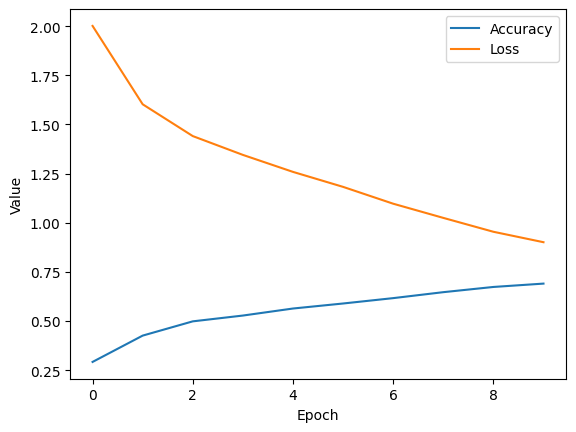

In [10]:
plt.plot(history.history['accuracy'], label='Accuracy')
plt.plot(history.history['loss'], label='Loss')
plt.xlabel('Epoch')
plt.ylabel('Value')
plt.legend()
plt.show()